<a href="https://colab.research.google.com/github/JSJeong-me/GPT-Agent/blob/main/06%20Deepagent/01_Multimodal_Document_Extraction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 | Multimodal Document Extraction — LangChain Deep Agents

**교육용 Google Colab Notebook · PDF / 이미지 정보 추출 · Custom Tools · 근거 검증**

**학습 성과**: (1) PDF 텍스트·표·페이지 이미지 추출 (2) 스캔 문서와 텍스트 PDF의 차이 (3) OpenAI Vision 기반 구조화 추출 (4) LangChain `@tool` 및 Deep Agent 호출 (5) 추출 결과의 원본 근거와 검증.

**실행 정책**: ① **API 없이 1~5단계 실행 가능** ② Vision 및 Agent 실습은 API Key와 모델 접근 권한이 있을 때만 수행 ③ 기본 예시는 *가상 MRO 업무 요청서*이며 회사 실제 문서는 업로드·전송 승인 후 사용합니다.

**기술 참고**: [Deep Agents Quickstart](https://docs.langchain.com/oss/python/deepagents/quickstart) · [Deep Agents Tools](https://docs.langchain.com/oss/python/deepagents/tools) · [PyMuPDF Page API](https://pymupdf.readthedocs.io/en/latest/page.html).

## 단계 안내 (권장 90~120분)

| 단계 | 주요 내용 | API 필요 |
|---|---|---|
| 1 | 환경 설정, 프로젝트 폴더 | 아니요 |
| 2 | 가상 PDF/이미지 생성 및 문서 확인 | 아니요 |
| 3 | PDF 텍스트·표·이미지 추출 | 아니요 |
| 4 | 페이지 이미지 렌더링, 스캔 감지 | 아니요 |
| 5 | LangChain Custom Tool 만들기와 직접 검사 | 아니요 |
| 6 | Vision LLM 구조화 정보 추출 | 예 |
| 7 | Deep Agent가 Tool을 선택하도록 통합 | 예 |
| 8 | 원본 근거 검증 / JSON·CSV 저장 | Vision 결과 사용 시 예 |

> Colab에서는 `런타임 → 모두 실행` 대신 **단계별 실행**을 권장합니다. 유료 API 단계는 명시적으로 켜야 합니다.

## 1. 개발 환경 설정

PyMuPDF는 PDF 내용을 읽고 페이지를 이미지로 렌더링하며, Pillow는 교육용 이미지를 생성합니다. LangChain은 Custom Tool과 ChatOpenAI를 연결하고, Deep Agents는 도구 호출을 오케스트레이션합니다.

In [1]:
%pip -q install -U pymupdf pillow pandas pydantic langchain-core langchain-openai deepagents

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.2 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
google-adk 2.7.1 requires google-genai<3,>=2.12.1, but you have google-genai 3.2.0 which is incompatible.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [1]:
import os, sys, json, base64, mimetypes
from pathlib import Path
import pandas as pd
import pymupdf
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display

IS_COLAB = 'google.colab' in sys.modules
ROOT = Path('/content/multimodal_document_extraction') if IS_COLAB else Path.cwd() / 'multimodal_document_extraction'
INPUT = ROOT / 'input'; OUTPUT = ROOT / 'output'; PAGE_DIR = OUTPUT / 'pages'
for folder in (INPUT, OUTPUT, PAGE_DIR): folder.mkdir(parents=True, exist_ok=True)
print('Project:', ROOT, '\nColab:', IS_COLAB)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Project: /content/multimodal_document_extraction 
Colab: True


## 2. 가상 MRO 요청서 생성 (실습용 입력 파일)

샘플에는 **텍스트 레이어를 가진 PDF 1페이지**, **스캔 이미지처럼 텍스트 레이어가 없는 2페이지**, **독립 PNG 이미지**를 만듭니다. 실제 기업 데이터가 아니며, 이후에 같은 입력 폴더에 사용자 PDF/PNG를 업로드해 실습할 수 있습니다.

PDF: /content/multimodal_document_extraction/input/demo_mro_requests.pdf
Image: /content/multimodal_document_extraction/input/demo_scanned_request.png


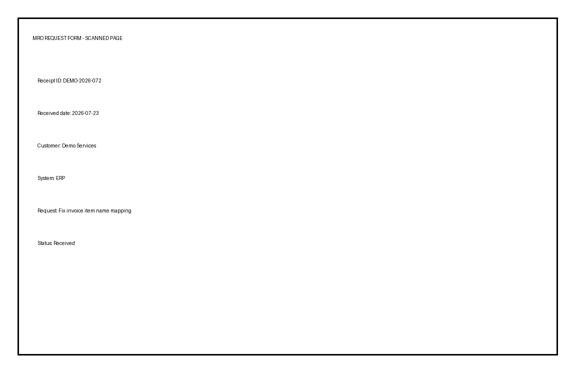

In [2]:
import sys
from pathlib import Path
from PIL import Image, ImageDraw, ImageFont
import pymupdf

# Ensure environment paths are defined
IS_COLAB = 'google.colab' in sys.modules
ROOT = Path('/content/multimodal_document_extraction') if IS_COLAB else Path.cwd() / 'multimodal_document_extraction'
INPUT = ROOT / 'input'
OUTPUT = ROOT / 'output'
PAGE_DIR = OUTPUT / 'pages'
for folder in (INPUT, OUTPUT, PAGE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# 샘플은 영문 표기지만 한국어 문서 분석에 쓰는 로직과 동일합니다.
# Colab 기본 환경의 글꼴 설치 여부에 영향받지 않도록 ASCII 텍스트로 생성합니다.
SAMPLE_FIELDS = {
    'receipt_id': 'DEMO-2026-071',
    'received_date': '2026-07-22',
    'customer': 'Demo Manufacturing',
    'system_name': 'MRO Portal',
    'request_description': 'Send automatic email two days before service date',
}

font_path = '/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf'
font = ImageFont.truetype(font_path, 24) if Path(font_path).exists() else ImageFont.load_default()
small_font = ImageFont.truetype(font_path, 19) if Path(font_path).exists() else ImageFont.load_default()

scan_image = Image.new('RGB', (1150, 750), 'white')
draw = ImageDraw.Draw(scan_image)
draw.rectangle((35,35,1115,710), outline='black', width=3)
draw.text((65,70), 'MRO REQUEST FORM - SCANNED PAGE', fill='black', font=font)
for idx, line in enumerate([
    'Receipt ID: DEMO-2026-072',
    'Received date: 2026-07-23',
    'Customer: Demo Services',
    'System: ERP',
    'Request: Fix invoice item name mapping',
    'Status: Received',
 ]):
    draw.text((75, 155+idx*65), line, fill='black', font=small_font)
scan_path = INPUT / 'demo_scanned_request.png'
scan_image.save(scan_path)

pdf_path = INPUT / 'demo_mro_requests.pdf'
doc = pymupdf.open()
p = doc.new_page(width=595, height=842)
lines = [
    'MRO REQUEST FORM - TEXT PDF',
    'Receipt ID: DEMO-2026-071',
    'Received date: 2026-07-22',
    'Customer: Demo Manufacturing',
    'System: MRO Portal',
    'Request: Send automatic email two days before service date',
    'Status: Deployment approved',
]
for idx, line in enumerate(lines):
    p.insert_text((55, 90+idx*40), line, fontsize=12 if idx else 16)
p2 = doc.new_page(width=595, height=842)
p2.insert_image(p2.rect, filename=str(scan_path), keep_proportion=True)
doc.save(str(pdf_path)); doc.close()
print(f'PDF: {pdf_path}\nImage: {scan_path}')
display(scan_image.resize((575,375)))

### 2-1. 내가 가진 PDF/이미지 업로드 (선택 사항)

다음 셀의 `USE_UPLOADED_FILES=True`로 바꾼 뒤 실행하면 Colab 파일 선택 창이 열립니다. 업로드된 PDF가 있으면 첫 PDF를 실습 대상으로 사용합니다. PNG/JPG는 Vision 실습에서 사용할 수 있습니다. **실제 문서의 외부 전송은 승인된 데이터만 허용**하세요.

In [3]:
USE_UPLOADED_FILES = True  # 필요할 때만 True
if USE_UPLOADED_FILES:
    if not IS_COLAB:
        print('Colab에서 실행하거나 파일을 직접 INPUT 폴더에 복사하세요.')
    else:
        from google.colab import files
        uploaded = files.upload()
        for filename, binary in uploaded.items():
            safe_name = Path(filename).name
            (INPUT / safe_name).write_bytes(binary)
        pdfs = sorted(INPUT.glob('*.pdf'))
        if pdfs:
            # 이름이 demo_가 아닌 PDF를 우선 선택
            user_pdfs = [p for p in pdfs if p.name != 'demo_mro_requests.pdf']
            if user_pdfs: pdf_path = user_pdfs[0]
        print('Selected PDF:', pdf_path)
else:
    print('교육용 PDF 사용:', pdf_path)

Saving demo_mro_requests.pdf to demo_mro_requests.pdf
Selected PDF: /content/multimodal_document_extraction/input/demo_mro_requests.pdf


## 3. PDF 텍스트 및 표 추출

`page.get_text()`는 PDF 텍스트 레이어에서 내용을 가져옵니다. 2페이지처럼 **이미지만 있는 스캔 PDF는 결과가 빈 문자열일 수 있습니다.** `find_tables()`는 PDF에 실제 표 테두리/정렬 정보가 있어야 검출되므로 빈 결과도 정상입니다.

In [4]:
def extract_pdf_local(path: str) -> list[dict]:
    records = []
    with pymupdf.open(path) as pdf:
        for page_num, page in enumerate(pdf, start=1):
            text = page.get_text('text', sort=True).strip()
            tables = []
            try:
                for table in page.find_tables().tables:
                    tables.append(table.extract())
            except Exception as exc:
                print(f'[표 검출 생략] page {page_num}: {exc}')
            records.append({
                'page': page_num,
                'text': text,
                'tables': tables,
                'needs_visual_review': len(text) < 25,
            })
    return records

pdf_records = extract_pdf_local(str(pdf_path))
for rec in pdf_records:
    print(f"PAGE {rec['page']} | text_chars={len(rec['text'])} | tables={len(rec['tables'])} | vision_candidate={rec['needs_visual_review']}")
    print(rec['text'][:550], '\n')

PAGE 1 | text_chars=220 | tables=0 | vision_candidate=False
MRO REQUEST FORM - TEXT PDF

Receipt ID: DEMO-2026-071

Received date: 2026-07-22

Customer: Demo Manufacturing

System: MRO Portal

Request: Send automatic email two days before service date

Status: Deployment approved 

PAGE 2 | text_chars=0 | tables=0 | vision_candidate=True
 



### 3-1. 표 탐지 결과 확인

테이블이 없다면 별도의 오류가 아닙니다. 이미지 기반 표는 페이지 이미지를 Vision LLM으로 읽어 구조화하거나, 별도 표 추출 모듈을 사용해야 합니다.

In [5]:
for rec in pdf_records:
    print(f"page={rec['page']}, found_tables={len(rec['tables'])}")
    for i, table in enumerate(rec['tables'], 1):
        print('table', i, table[:3])

page=1, found_tables=0
page=2, found_tables=0


## 4. PDF 페이지를 이미지로 변환

원본 전체 페이지를 PNG로 렌더링하면 스캔 PDF나 도표가 포함된 페이지도 Vision LLM에 전달할 수 있습니다. 페이지 번호는 1부터 시작하고, 파일 이름에 번호를 넣어 추적할 수 있게 합니다.

[{'page': 1, 'image_path': '/content/multimodal_document_extraction/output/pages/page_001.png'}, {'page': 2, 'image_path': '/content/multimodal_document_extraction/output/pages/page_002.png'}]


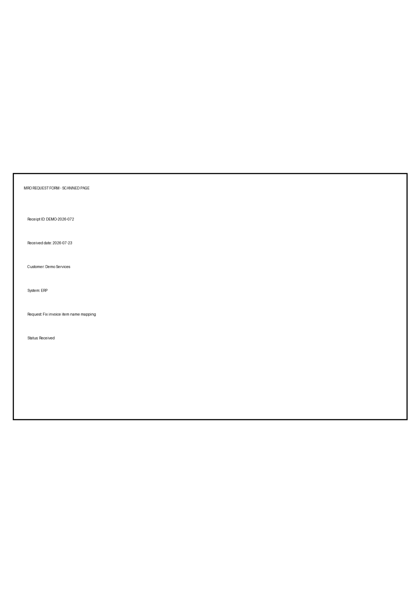

In [6]:
def render_pdf_pages(path: str, out_dir: Path, dpi: int = 140) -> list[dict]:
    out_dir.mkdir(parents=True, exist_ok=True)
    results = []
    with pymupdf.open(path) as pdf:
        for i, page in enumerate(pdf, 1):
            out = out_dir / f'page_{i:03d}.png'
            page.get_pixmap(dpi=dpi, alpha=False).save(str(out))
            results.append({'page': i, 'image_path': str(out)})
    return results

page_images = render_pdf_pages(str(pdf_path), PAGE_DIR)
print(page_images)
display(Image.open(page_images[1]['image_path']).resize((420,595)))

### 4-1. 자동 분기 규칙

텍스트 레이어가 충분한 페이지는 먼저 텍스트 추출을 사용합니다. 텍스트가 너무 적거나 이미지·도표가 핵심인 페이지는 Vision 분석 후보로 분류합니다. **이 규칙은 휴리스틱**이며 텍스트가 존재하더라도 표/그림이 중요한 페이지는 추가로 Vision 분석해야 합니다.

In [7]:
import pandas as pd

routing = pd.DataFrame([{
    'page': r['page'],
    'text_chars': len(r['text']),
    'route': 'VISION_REVIEW' if r['needs_visual_review'] else 'TEXT_FIRST',
    'image_path': page_images[r['page']-1]['image_path']
} for r in pdf_records])
display(routing)

,page,text_chars,route,image_path
0,1,220,TEXT_FIRST,/content/multimodal_document_extraction/output...
1,2,0,VISION_REVIEW,/content/multimodal_document_extraction/output...


## 5. LangChain Custom Tools 생성 및 단독 테스트

Agent에 연결하기 전에 **각 도구를 독립적으로 검증**합니다. 실습용 파일 경로 제한을 둬서 Tool이 프로젝트 입력 폴더 밖의 임의 파일을 읽지 않도록 합니다.

In [8]:
import json
from langchain_core.tools import tool

ALLOWED_ROOT = INPUT.resolve()
def ensure_allowed_file(path: str, extensions: tuple[str,...]) -> Path:
    p = Path(path).resolve()
    if not p.is_file() or not p.is_relative_to(ALLOWED_ROOT):
        raise ValueError('허용된 input 폴더 안의 파일만 읽을 수 있습니다.')
    if p.suffix.lower() not in extensions:
        raise ValueError(f'지원하지 않는 확장자: {p.suffix}')
    return p

@tool
def extract_pdf_text(pdf_file: str) -> str:
    """PDF 파일에서 페이지별 텍스트를 추출하고 Vision 검토 필요 여부를 반환한다.

    Args:
        pdf_file: input 폴더 안의 절대 경로 PDF.
    """
    p = ensure_allowed_file(pdf_file, ('.pdf',))
    return json.dumps(extract_pdf_local(str(p)), ensure_ascii=False)[:18000]

@tool
def inspect_document_file(file_path: str) -> str:
    """입력 폴더의 PDF 또는 이미지 파일의 기본 메타데이터를 확인한다.

    Args:
        file_path: input 폴더 안의 절대 경로 PDF/PNG/JPG.
    """
    p = ensure_allowed_file(file_path, ('.pdf','.png','.jpg','.jpeg'))
    if p.suffix.lower() == '.pdf':
        with pymupdf.open(str(p)) as d:
            info = {'type':'pdf', 'pages':len(d), 'bytes':p.stat().st_size}
    else:
        with Image.open(p) as im:
            info = {'type':'image','width':im.width,'height':im.height,'bytes':p.stat().st_size}
    return json.dumps({'name':p.name, **info}, ensure_ascii=False)

print(inspect_document_file.invoke({'file_path':str(pdf_path)}))
print(extract_pdf_text.invoke({'pdf_file':str(pdf_path)})[:700])

{"name": "demo_mro_requests.pdf", "type": "pdf", "pages": 2, "bytes": 2592733}
[{"page": 1, "text": "MRO REQUEST FORM - TEXT PDF\n\nReceipt ID: DEMO-2026-071\n\nReceived date: 2026-07-22\n\nCustomer: Demo Manufacturing\n\nSystem: MRO Portal\n\nRequest: Send automatic email two days before service date\n\nStatus: Deployment approved", "tables": [], "needs_visual_review": false}, {"page": 2, "text": "", "tables": [], "needs_visual_review": true}]


## 6. OpenAI Vision으로 구조화 추출 (선택 · API 요금 발생)

이 단계는 PDF의 **이미지 페이지(2쪽)**에서 접수번호·일자·고객사·시스템·요청내용을 추출합니다. LangChain `ChatOpenAI`와 Pydantic 모델로 구조화 출력을 요청하고, 응답에는 원본 페이지 번호를 붙입니다.

**보안**: 사내 문서를 올리거나 호출하기 전에 외부 API 전송 승인을 확인하세요. Vision LLM 출력은 추출 후보이며 원본 검증 없이 확정하지 않습니다.

In [9]:
import os
# API 호출은 기본 비활성화: True로 바꾸어야 이후 유료 실습을 수행합니다.
ENABLE_OPENAI = True
MODEL_ID = 'gpt-4.1-mini'  # API 계정에서 사용 가능한 vision+tool calling 모델로 변경 가능

if ENABLE_OPENAI:
    try:
        from google.colab import userdata
        api_key = userdata.get('OPENAI_API_KEY')
        if api_key:
            os.environ['OPENAI_API_KEY'] = api_key
    except (ImportError, ModuleNotFoundError):
        pass
    if not os.getenv('OPENAI_API_KEY'):
        from getpass import getpass
        os.environ['OPENAI_API_KEY'] = getpass('OpenAI API Key: ').strip()
    assert os.getenv('OPENAI_API_KEY'), 'OPENAI_API_KEY 누락'
else:
    print('OpenAI API 비활성 상태. ENABLE_OPENAI=True로 변경하면 6~7단계를 실행합니다.')

### 6-1. 구조화 출력 스키마 정의

추출이 불확실하거나 문서에 없는 필드는 `None`으로 유지합니다. 특히 문서에 없는 처리상태를 임의 생성하지 않도록 명시합니다.

In [10]:
from pydantic import BaseModel, Field
from typing import Optional

class RequestExtraction(BaseModel):
    receipt_id: Optional[str] = Field(default=None, description='문서의 접수번호')
    received_date: Optional[str] = Field(default=None, description='YYYY-MM-DD 형태의 접수일자')
    customer: Optional[str] = Field(default=None, description='고객사')
    system_name: Optional[str] = Field(default=None, description='대상 업무 시스템')
    request_description: Optional[str] = Field(default=None, description='요청내용')
    processing_status: Optional[str] = Field(default=None, description='문서에 명시된 처리상태')
    uncertain_fields: list[str] = Field(default_factory=list, description='시각적으로 확실하지 않은 항목 이름')

print('Schema fields:', list(RequestExtraction.model_fields))

Schema fields: ['receipt_id', 'received_date', 'customer', 'system_name', 'request_description', 'processing_status', 'uncertain_fields']


### 6-2. LangChain Vision 호출

이미지를 Base64 data URI로 전달합니다. 실제 호출 시 구조화 결과와 메타데이터(원본 파일·페이지)를 함께 저장합니다. 모델은 이미지에서 읽은 정보를 보조하며, 확정 판정은 추후 별도 검증에서 수행합니다.

In [11]:
import mimetypes
import base64
from pathlib import Path
from langchain_openai import ChatOpenAI
from langchain_core.messages import HumanMessage

def image_data_url(image_path: str) -> str:
    p = Path(image_path)
    mime = mimetypes.guess_type(str(p))[0] or 'image/png'
    return f'data:{mime};base64,' + base64.b64encode(p.read_bytes()).decode('ascii')

def vision_extract(image_path: str, model_id: str = MODEL_ID) -> dict:
    p = ensure_allowed_file(image_path, ('.png','.jpg','.jpeg')) if Path(image_path).resolve().is_relative_to(INPUT.resolve()) else Path(image_path).resolve()
    # 페이지 렌더링 결과는 output/pages 하위만 추가 허용
    if not (p.is_file() and (p.is_relative_to(INPUT.resolve()) or p.is_relative_to(PAGE_DIR.resolve()))):
        raise ValueError('허용되지 않은 이미지 경로입니다.')
    llm = ChatOpenAI(model=model_id).with_structured_output(RequestExtraction)
    msg = HumanMessage(content=[
        {'type':'text','text': '이 업무 요청서 이미지를 읽어 기재된 사실만 추출하세요. 안 보이면 null로 두고 uncertain_fields에 적으세요.'},
        {'type':'image_url','image_url':{'url': image_data_url(str(p))}},
    ])
    parsed = llm.invoke([msg])
    return parsed.model_dump()

vision_result = None
if ENABLE_OPENAI:
    image_to_analyze = page_images[1]['image_path']
    vision_result = vision_extract(image_to_analyze)
    print(json.dumps(vision_result, ensure_ascii=False, indent=2))
else:
    print('Vision API 호출 생략. 로컬 PDF 추출 결과는 계속 사용 가능합니다.')

{
  "receipt_id": "DEMO-2026-072",
  "received_date": "2026-07-23",
  "customer": "Demo Services",
  "system_name": "ERP",
  "request_description": "Fix invoice item name mapping",
  "processing_status": "Received",
  "uncertain_fields": []
}


## 7. LangChain Deep Agent + Custom Tools 통합 (선택 · API 요금 발생)

이 예제에서는 Agent가 먼저 파일을 검사하고, 필요한 경우 텍스트 추출 Tool을 호출하도록 유도합니다. 이미지 분석은 별도의 Vision Custom Tool로 제공합니다. Tool 호출 기록을 출력하여 실제로 어떤 도구를 사용했는지 확인합니다.

**주의**: LLM이 선택하는 Tool 순서는 보장되지 않습니다. 로컬 파일의 입력·출력 접근 범위는 Custom Tool에서 제한합니다.

In [12]:
@tool
def analyze_request_image(image_file: str) -> str:
    """업무 요청서 PNG/JPG 또는 PDF 렌더링 페이지 이미지에서 필드를 추출한다.

    Args:
        image_file: input 폴더 또는 output/pages 폴더의 이미지 절대 경로.
    """
    if not ENABLE_OPENAI:
        return 'Vision API disabled: ENABLE_OPENAI must be True.'
    return json.dumps(vision_extract(image_file), ensure_ascii=False)

TOOLS = [inspect_document_file, extract_pdf_text, analyze_request_image]
print([(t.name, t.description[:90]) for t in TOOLS])

[('inspect_document_file', '입력 폴더의 PDF 또는 이미지 파일의 기본 메타데이터를 확인한다.\n\nArgs:\n    file_path: input 폴더 안의 절대 경로 PDF/PNG/JPG.'), ('extract_pdf_text', 'PDF 파일에서 페이지별 텍스트를 추출하고 Vision 검토 필요 여부를 반환한다.\n\nArgs:\n    pdf_file: input 폴더 안의 절대 경로 PDF.'), ('analyze_request_image', '업무 요청서 PNG/JPG 또는 PDF 렌더링 페이지 이미지에서 필드를 추출한다.\n\nArgs:\n    image_file: input 폴더 또는 output/pa')]


In [13]:
from deepagents import create_deep_agent
from langchain_core.messages import AIMessage, ToolMessage

agent_result = None
if ENABLE_OPENAI:
    agent = create_deep_agent(
        model=f'openai:{MODEL_ID}',
        tools=TOOLS,
        system_prompt=(
            '당신은 MRO 업무 문서 추출 Agent입니다. 파일 내용을 추측하지 마세요. '
            '문서 메타데이터 확인 → PDF 텍스트 추출 → 스캔 페이지면 Vision 분석 순서로 작업하세요. '
            'Tool이 제공한 값에 근거하여 접수번호/날짜/고객사/요구사항을 요약하세요. '
            '사용자 파일을 수정하지 마세요.'
        ),
    )
    # 기존 가상 예시만 자동 호출; 실제 고객 데이터로 바꾸기 전 전송 정책 확인
    demo_pdf = str(INPUT / 'demo_mro_requests.pdf')
    demo_image = str(PAGE_DIR / 'page_002.png')
    agent_result = agent.invoke({'messages': [
        {'role':'user','content':f'이 PDF를 분석하세요: {demo_pdf}. '
                                 f'2페이지는 이미지이므로 {demo_image}를 분석하고 '
                                 '1·2페이지의 접수번호, 고객사, 요청내용을 각각 제시하세요.'}
    ]}, config={'recursion_limit': 30})
    print('FINAL:', agent_result['messages'][-1].content)
else:
    print('Agent 호출 생략 (ENABLE_OPENAI=False).')

FINAL: [{'type': 'text', 'text': '1페이지 정보:\n- 접수번호: DEMO-2026-071\n- 고객사: Demo Manufacturing\n- 요청내용: 서비스일 2일 전 자동 이메일 발송 요청\n\n2페이지 정보:\n- 접수번호: DEMO-2026-072\n- 고객사: Demo Services\n- 요청내용: 송장 항목명 매핑 수정 요청\n\n요약 완료했습니다. 추가로 궁금한 점 있으면 알려주세요.', 'annotations': [], 'id': 'msg_0e2ff1b7c6dc3349006af56a1ef46487d1a14b72598506dd65'}]


### 7-1. 실행 로그에서 실제 Tool 호출 확인

답변에 근거가 있다고 쓰여 있는 것만으로 실제 Tool을 호출했다고 증명할 수 없습니다. 각 `AIMessage.tool_calls`와 `ToolMessage`를 확인합니다.

In [14]:
if agent_result is not None:
    for msg in agent_result['messages']:
        if isinstance(msg, AIMessage) and msg.tool_calls:
            for call in msg.tool_calls:
                print('[TOOL CALL]', call['name'], call.get('args'))
        elif isinstance(msg, ToolMessage):
            print('[TOOL RESULT]', msg.name, str(msg.content)[:350])
else:
    print('Agent 실행 후 이 셀을 다시 실행하세요.')

[TOOL CALL] extract_pdf_text {'pdf_file': '/content/multimodal_document_extraction/input/demo_mro_requests.pdf'}
[TOOL CALL] analyze_request_image {'image_file': '/content/multimodal_document_extraction/output/pages/page_002.png'}
[TOOL RESULT] extract_pdf_text [{"page": 1, "text": "MRO REQUEST FORM - TEXT PDF\n\nReceipt ID: DEMO-2026-071\n\nReceived date: 2026-07-22\n\nCustomer: Demo Manufacturing\n\nSystem: MRO Portal\n\nRequest: Send automatic email two days before service date\n\nStatus: Deployment approved", "tables": [], "needs_visual_review": false}, {"page": 2, "text": "", "tables": [], "needs_vis
[TOOL RESULT] analyze_request_image {"receipt_id": "DEMO-2026-072", "received_date": "2026-07-23", "customer": "Demo Services", "system_name": "ERP", "request_description": "Fix invoice item name mapping", "processing_status": "Received", "uncertain_fields": []}


## 8. 원본 근거 보존 · 결과 검증 · 파일 출력

단계별 산출물을 JSON/CSV로 저장합니다. API 실행 여부와 무관하게 **페이지별 PDF 텍스트와 라우팅 분석**을 저장합니다. Vision 결과는 실제 호출한 경우에만 저장하며, 임의의 답을 생성하지 않습니다.

In [15]:
(OUTPUT / 'pdf_page_extraction.json').write_text(
    json.dumps(pdf_records, ensure_ascii=False, indent=2), encoding='utf-8'
)
routing.to_csv(OUTPUT / 'page_routing.csv', index=False, encoding='utf-8-sig')

if vision_result is not None:
    document_result = {
        'source_file': pdf_path.name,
        'source_page': 2,
        'extractor': MODEL_ID,
        'extracted': vision_result,
        'review_status': 'REVIEW_REQUIRED',
    }
    (OUTPUT / 'vision_result.json').write_text(
        json.dumps(document_result, ensure_ascii=False, indent=2), encoding='utf-8'
    )

print('Saved files:')
for item in sorted(OUTPUT.rglob('*')):
    if item.is_file(): print(' -', item.relative_to(ROOT))

Saved files:
 - output/page_routing.csv
 - output/pages/page_001.png
 - output/pages/page_002.png
 - output/pdf_page_extraction.json
 - output/vision_result.json


### 8-1. 교육용 정답 비교 (가상 1페이지에 한함)

1페이지는 텍스트 레이어가 있어 **기대값**과 추출된 문자열을 자동 비교할 수 있습니다. 이 검사는 샘플 교육용의 단순 검증이며 실제 현업에는 날짜 정규화, 중복 판단, 근거 페이지, 필드별 정확도가 필요합니다.

In [16]:
page1_text = pdf_records[0]['text']
checks = {name: str(value).lower() in page1_text.lower()
          for name, value in SAMPLE_FIELDS.items()}
print(pd.DataFrame([{'field':k,'expected':v,'found_in_pdf':checks[k]}
                    for k,v in SAMPLE_FIELDS.items()]))
print('PASS' if all(checks.values()) else 'REVIEW_REQUIRED')

assert 'DEMO-2026-071' in page1_text, '기본 샘플 PDF 생성/추출 점검 필요'
assert pdf_records[1]['needs_visual_review'], '스캔 페이지 라우팅 점검 필요'
print('Local validation passed: text-layer PDF and scanned-page routing.')

                 field                                           expected  \
0           receipt_id                                      DEMO-2026-071   
1        received_date                                         2026-07-22   
2             customer                                 Demo Manufacturing   
3          system_name                                         MRO Portal   
4  request_description  Send automatic email two days before service date   

   found_in_pdf  
0          True  
1          True  
2          True  
3          True  
4          True  
PASS
Local validation passed: text-layer PDF and scanned-page routing.


### 8-2. Colab에서 결과 다운로드 (선택)

출력물 전체를 ZIP으로 묶어 내려받습니다. 내부에 추출 텍스트 및 이미지가 포함되므로 개인정보가 들어 있는 회사 문서일 경우 보안 규정을 준수하세요.

In [17]:
import shutil
zip_path = shutil.make_archive(str(ROOT / '01_document_extraction_outputs'), 'zip', root_dir=OUTPUT)
print(zip_path)
if IS_COLAB:
    from google.colab import files
    # 자동 다운로드가 필요할 때 다음 줄의 주석을 해제하세요.
    # files.download(zip_path)

/content/multimodal_document_extraction/01_document_extraction_outputs.zip


## 9. 확인 문제 및 다음 실습

**확인 문제**
1. 2페이지 텍스트 길이가 짧게 나타나는 이유는 무엇인가요?
2. PDF에서 표가 이미지로 들어 있는 경우 `find_tables()` 결과는 언제 비어 있을 수 있나요?
3. 원본에 없는 고객사 정보를 Vision LLM이 생성했다면 어떻게 처리해야 하나요?
4. Agent의 Tool Calling이 실제로 수행되었다는 것을 어떤 로그로 검증하나요?
5. `REVIEW_REQUIRED`가 필요한 사례를 2개 들어 보세요.

**다음 강의**: `02_Structured_Excel_Automation.ipynb`에서 이번 결과에 `Pydantic` 스키마 검증·날짜 정규화·Excel 자동 생성을 연결합니다.

**운영 유의사항**: API Key를 노트북에 평문으로 저장하지 마세요. 실제 데이터는 외부 API 및 자동화 도구에 전달하기 전에 권한과 데이터 반출 정책을 검토하세요.